<a href="https://colab.research.google.com/github/Minimire/README.md/blob/main/Copy_of_Module_6_pythons.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#CELL 1-install dependencies & load  dataset
print("\n"+"#"*50+"\n")
!pip install -q xgboost shap optuna openpyxl joblib
import os,warnings,joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
SEEDS=[0,42,123]
RANDOM_STATE=SEEDS
np.random.seed(RANDOM_STATE)
print("\n3-tier dataset loader")
print("\n"+"#"*50+"\n")
DATA_XLSX="Crop_recommendation.xlsx"
DATA_CSV="Crop_recommendation.csv"
# Fixed case-sensitivity: 'Data_Processed' instead of 'Data_processed'
URL="https://raw.githubusercontent.com/Gladiator07/Harvestify/master/Data-processed/crop_recommendation.csv"
if os.path.exists(DATA_XLSX):
   df=pd.read_excel(DATA_XLSX)
   print(f"LOADED {DATA_XLSX}")
elif os.path.exists(DATA_CSV):
   df=pd.read_csv(DATA_CSV)
   print(f"LOADED {DATA_CSV}")
else:
   df=pd.read_csv(URL)
   print(f"LOADED FROM THE URL THAT IS (SAME KAGGLE DATA)")
print(f"shape:{df.shape}")
print(f"Columns:{list(df.columns)}")
df.head()


##################################################


3-tier dataset loader

##################################################

LOADED FROM THE URL THAT IS (SAME KAGGLE DATA)
shape:(2200, 8)
Columns:['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'label']


,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice



##################################################


CHECKING THE DATASET FOR THE MISSING VALUES,DUPLICATED,MAKING THE CLASS COUNT AND PLOT THE DISTRIBUTION,CORRELATIONS

##################################################


CHECKING ON THE CLEANENESS OF DATASE
MISSING VALUES: 0
Count Duplicate rows: 0
The Classes counts: 22
Samples per class: [100]
Soil pH mean: 6.47
Rainfall mean: 20.2 -> 298.6
TEMPERATURE: 9.0 -> 43.67549305
TEMPERATURE MEAN: 25.6162438518
HUMIDITY: 14.26 -> 99.98187601
HUMIDITY MEAN: 71.4818

##################################################

PLOT THE DISTRIBUTIOM OF THE CLASSES

##################################################



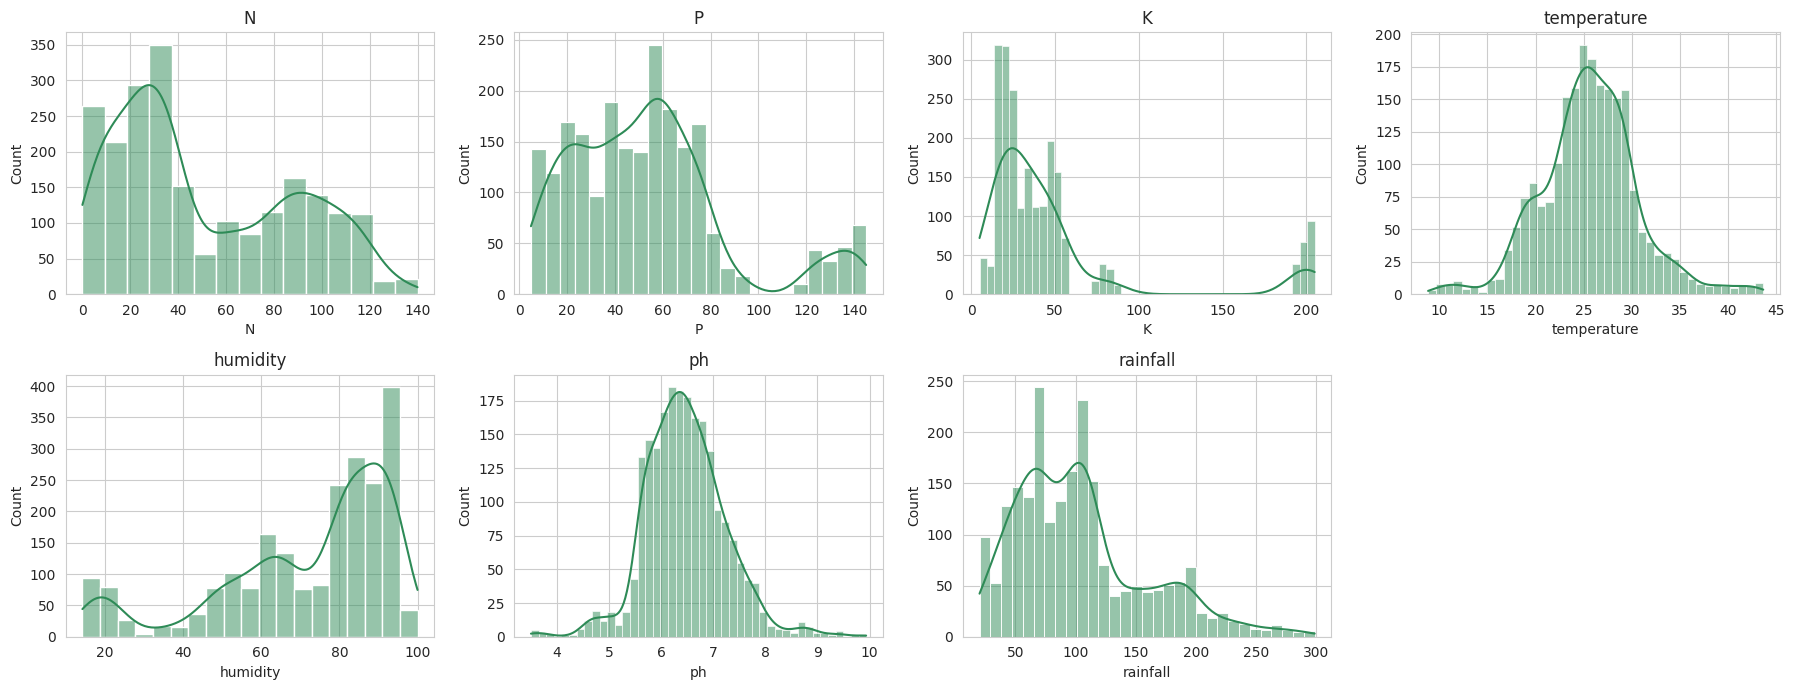


##################################################

PLOT THE CORRELATION BETWEEN THE FEATURES

##################################################



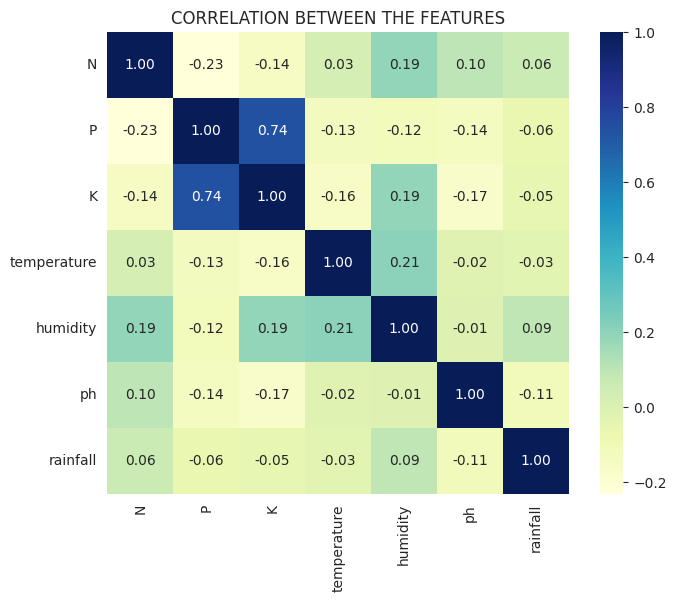


##################################################

PLOT THE RAINFALL FOR EVERY CROP:(RICE THRESHOLD INSIGHT)

##################################################



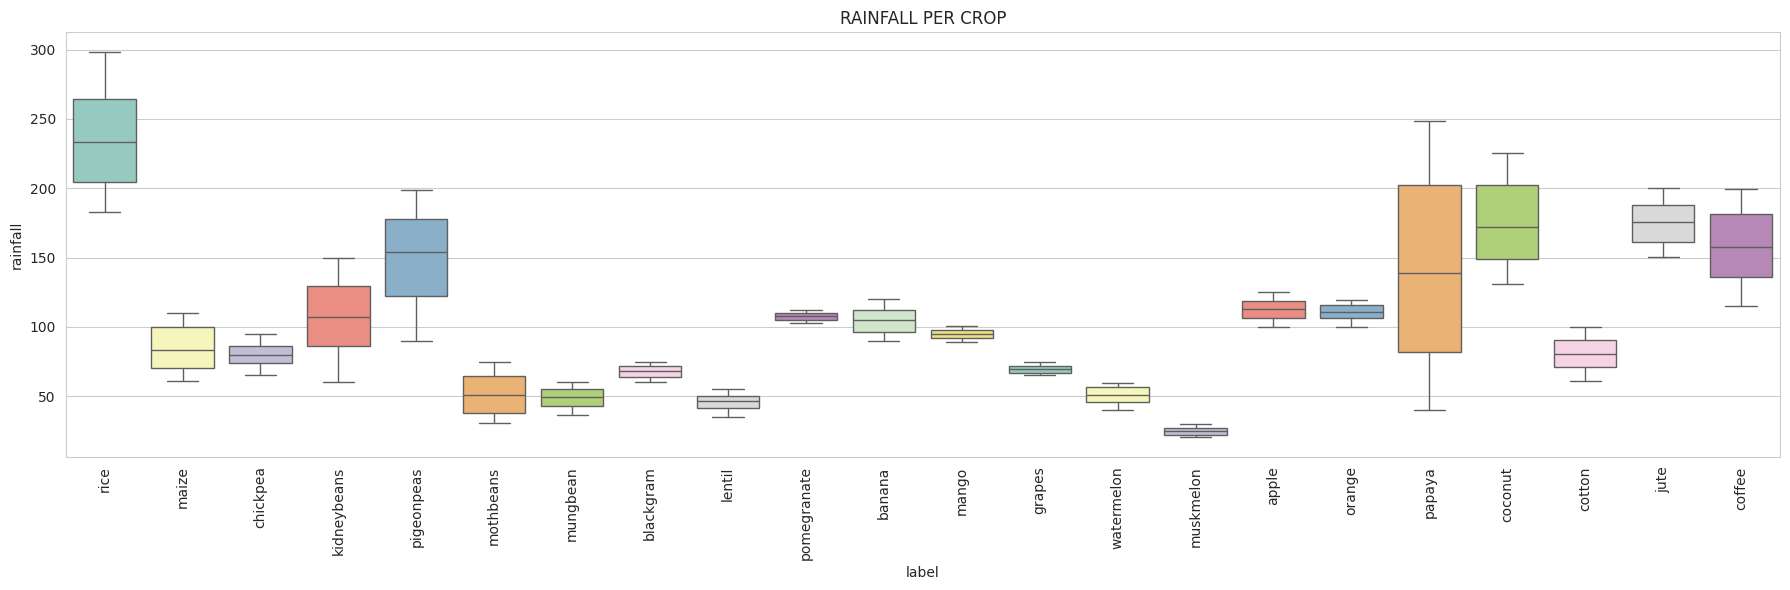


##################################################


TOP-5 HIGH - POTASSIIUM CROPS:

##################################################

label
grapes        200.1
apple         199.9
chickpea       79.9
watermelon     50.2
muskmelon      50.1
Name: K, dtype: float64


In [ ]:
#CELL-2 ON DATASET CHECKS AND CLEANING
print("\n"+"#"*50+"\n")
print("\nCHECKING THE DATASET FOR THE MISSING VALUES,DUPLICATED,MAKING THE CLASS COUNT AND PLOT THE DISTRIBUTION,CORRELATIONS")
print("\n"+"#"*50+"\n")
# Columns in DataFrame are lowercase: ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'label']
FEATURES=["N","P","K","temperature","humidity","ph","rainfall"]
print("\nCHECKING ON THE CLEANENESS OF DATASE")
print("MISSING VALUES:",int(df.isnull().sum().sum()))
print("Count Duplicate rows:",int(df.duplicated().sum()))
print("The Classes counts:",df["label"].nunique())
print("Samples per class:",df["label"].value_counts().unique())
print("Soil pH mean:",round(df["ph"].mean(),2))
print("Rainfall mean:",round(df["rainfall"].min(),1),"->",round(df["rainfall"].max(),1))
print("TEMPERATURE:",round(df["temperature"].min(),0),"->",round(df["temperature"].max(),100))
print("TEMPERATURE MEAN:",round(df["temperature"].mean(),10))
print("HUMIDITY:",round(df["humidity"].min(),2),"->",round(df["humidity"].max(),50))
print("HUMIDITY MEAN:",round(df["humidity"].mean(),4))
print("\n"+"#"*50+"\n")
print("PLOT THE DISTRIBUTIOM OF THE CLASSES")
print("\n"+"#"*50+"\n")
#PLOT THE CLASS DISTRIBUTION
fig,axes=plt.subplots(nrows=2,ncols=4,figsize=(18,7))
axes = axes.flatten() # Fixed: assigned the flattened array back to axes
for i,col in enumerate(FEATURES):
  sns.histplot(df[col],kde=True,ax=axes[i],color="seagreen") # Fixed color name typo
  axes[i].set_title(col)
axes[-1].axis("off")
plt.tight_layout()
plt.show()
print("\n"+"#"*50+"\n")
print("PLOT THE CORRELATION BETWEEN THE FEATURES")
print("\n"+"#"*50+"\n")
#PLOT FOR THE CORRELATION ESTABLISHED AMONG THE FEATURES
plt.figure(figsize=(8,6))
sns.heatmap(df[FEATURES].corr(),annot=True,fmt=".2f",cmap="YlGnBu",square=True)
plt.title("CORRELATION BETWEEN THE FEATURES");
plt.show()
print("\n"+"#"*50+"\n")
print("PLOT THE RAINFALL FOR EVERY CROP:(RICE THRESHOLD INSIGHT)")
print("\n"+"#"*50+"\n")
#THE RAINFALL PLOT AGAINST EVERY CROP
plt.figure(figsize=(18,6)) # Fixed: 'figsiz' to 'figsize'
sns.boxplot(data=df,x="label",y="rainfall",palette="Set3")
plt.xticks(rotation=90);
plt.title("RAINFALL PER CROP");
plt.tight_layout();
plt.show()
print("\n"+"#"*50+"\n")
print("\nTOP-5 HIGH - POTASSIIUM CROPS:")
print("\n"+"#"*50+"\n")
print(df.groupby("label")["K"].mean().sort_values(ascending=False).head(5).round(1))

In [ ]:
#CELL-3: ON DATA PREPOCESSING
print("\n"+"#"*50+"\n")
print("\nDATA PREPROCESSING")
print("\n"+"#"*50+"\n")
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
X=df[FEATURES].copy()
y_raw=df["label"].copy()
label_encoder=LabelEncoder()
y=label_encoder.fit_transform(y_raw)
print("Encoded Classes(22):")
for i,c in enumerate(label_encoder.classes_):
  print(f"{i:2d}->{c}")
  X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
  print("\n"+"#"*50+"\n")
  print(f"\nTRAIN:{X_train.shape}|TEST:{X_test.shape}")
  print("\nSCALER FITING ON THE TRAINING ONLY HENCE AVOID DATA LEAKADE")
  scaler=StandardScaler()
  X_train=scaler.fit_transform(X_train)
  X_test=scaler.transform(X_test)   #THE FITTING ONLY ABOUT THE TRAINING NOT ONTO THE X_TEST
  print("\nSAVE PREPROCESSING ARTIFACTS")
  joblib.dump(scaler,"scaler.joblib")
  joblib.dump({"features":FEATURES,"label_encoder":label_encoder,"scaler":scaler},"preprocessing.pkl")
  print("Saved preprocessing.pkl")


##################################################


DATA PREPROCESSING

##################################################

Encoded Classes(22):
 0->apple

##################################################


TRAIN:(1760, 7)|TEST:(440, 7)

SCALER FITING ON THE TRAINING ONLY HENCE AVOID DATA LEAKADE

SAVE PREPROCESSING ARTIFACTS
Saved preprocessing.pkl
 1->banana

##################################################


TRAIN:(1760, 7)|TEST:(440, 7)

SCALER FITING ON THE TRAINING ONLY HENCE AVOID DATA LEAKADE

SAVE PREPROCESSING ARTIFACTS
Saved preprocessing.pkl
 2->blackgram

##################################################


TRAIN:(1760, 7)|TEST:(440, 7)

SCALER FITING ON THE TRAINING ONLY HENCE AVOID DATA LEAKADE

SAVE PREPROCESSING ARTIFACTS
Saved preprocessing.pkl
 3->chickpea

##################################################


TRAIN:(1760, 7)|TEST:(440, 7)

SCALER FITING ON THE TRAINING ONLY HENCE AVOID DATA LEAKADE

SAVE PREPROCESSING ARTIFACTS
Saved preprocessing.pkl
 4->cocon

In [ ]:
#CELL-4; ON THE SEED-ROBUSTNESS AUDIT FOR RF AND XGB
print("\nSEED-ROBUSTNESS AUDIT FOR THE RANDOM FOREST AND XGBOOST")
print("\n"+"#"*50+"\n")
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score
import numpy as np
SEEDS=[0,42,123]
RANDOM_STATE=SEEDS   # Model seed fixed at 42 so we measure SPLIT variance only, not model randomness.
rf_accs,xgb_accs=[],[]
for seed in SEEDS:
  Xtr,Xte,ytr,yte=train_test_split(X,y,test_size=0.2,random_state=seed,stratify=y)
rf=RandomForestClassifier(n_estimators=500,random_state=42,n_jobs=-1).fit(Xtr,ytr)
rf_acc=accuracy_score(yte,rf.predict(Xte))
rf_accs.append(rf_acc)
xgb=XGBClassifier(n_estimators=200,learning_rate=0.1,random_state=42,max_depth=5,objective="multi:softprob",num_class=22,n_jobs=-1,eval_metric="mlogloss",tree_methods="hist").fit(Xtr,ytr)
xgb_acc=accuracy_score(yte,xgb.predict(Xte))
xgb_accs.append(xgb_acc)
print(f"seed{seed:3d}|RF={rf_acc:.4f}(+/-{np.std(rf_accs):.4f})|XGB={xgb_acc:.4f}(+/-{np.std(xgb_accs):.4f})")
print(f"seed{seed:3d}|RF={rf_acc:.4f}({rf_acc*100:.2f}%)"f"|XGB={xgb_acc:.4f}({xgb_acc*100:.2f}%)")
print("\n"+"#"*50+"\n")
print(f"RandomForest:{np.mean(rf_accs):.4f}+/-{np.std(rf_accs):.4f}"f"({np.mean(rf_accs)*100:.2f}%+/-{np.std(rf_accs)*100:.2f}%)")
print(f"XGBoost:{np.mean(xgb_accs):.4f}+/-{np.std(xgb_acc):.4f}"f"({np.mean(xgb_accs)*100:.2f}%{np.std(xgb_accs)*100:.2f}%)")
print("\n"+"#"*50+"\n")
print(f"Range(RF):{min(rf_accs)*100:.2f}%->{max(rf_accs)*100:.2f}%")


SEED-ROBUSTNESS AUDIT FOR THE RANDOM FOREST AND XGBOOST

##################################################

seed123|RF=0.9932(+/-0.0000)|XGB=0.9909(+/-0.0000)
seed123|RF=0.9932(99.32%)|XGB=0.9909(99.09%)

##################################################

RandomForest:0.9932+/-0.0000(99.32%+/-0.00%)
XGBoost:0.9909+/-0.0000(99.09%0.00%)

##################################################

Range(RF):99.32%->99.32%


In [ ]:
# CELL-5: ON TRAINIG AND COMPARING ALL MODELS
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score
import pandas as pd
from sklearn.preprocessing import StandardScaler

# Using 42 directly to avoid the list of seeds issue from CELL-4
models={
    "Dummy":DummyClassifier(strategy="most_frequent"),
    "Logistic Regression":Pipeline([("sc",StandardScaler()),("clf",LogisticRegression(max_iter=2000,random_state=42))]),
    "KNN(k=5)":Pipeline([("sc",StandardScaler()),("clf",KNeighborsClassifier(n_neighbors=5))]),
    "Random Forest":RandomForestClassifier(n_estimators=500,random_state=42,n_jobs=-1),
    "XGBoost":XGBClassifier(n_estimators=200,learning_rate=0.1,max_depth=5,objective="multi:softprob",num_class=22,eval_metric="mlogloss",tree_method="hist",random_state=42),
    }
rows,trained=[],{}
for name,m in models.items():
   m.fit(X_train,y_train)
   p=m.predict(X_test)
   trained[name]=m
   rows.append({"Model":name,
               "Accuracy":accuracy_score(y_test,p),
               "Precision":precision_score(y_test,p,average="macro",zero_division=0),
               "Recall":recall_score(y_test,p,average="macro",zero_division=0),
               "F1":f1_score(y_test,p,average="macro",zero_division=0)})
results=pd.DataFrame(rows).sort_values("Accuracy",ascending=False).reset_index(drop=True)
display(results.style.format({"Accuracy":"{:.2%}","Precision":"{:.2%}","Recall":"{:.2%}","F1":"{:.2%}"}))

,Model,Accuracy,Precision,Recall,F1
0,Random Forest,99.55%,99.57%,99.55%,99.55%
1,XGBoost,98.64%,98.74%,98.64%,98.62%
2,KNN(k=5),97.95%,98.04%,97.95%,97.93%
3,Logistic Regression,97.27%,97.40%,97.27%,97.25%
4,Dummy,4.55%,0.21%,4.55%,0.40%


In [ ]:
#CELL-6; ON TUNED THE RANDOM FOREST WITH GRIDSEARCH CV ACROSS MULTIPLE SEEDS
print("\n"+"#"*50+"\n")
print("\nTHE RESULT FOR RANDOM FOREST MODEL TUNED UNDER GRIDSEARCH CV ACROSS SEEDS")
print("\n"+"#"*50+"\n")
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
import numpy as np

param_grid={
    "n_estimators":[200,500,800],
    "max_depth":[None,15,25],
    "max_features":["sqrt","log2"],
}

# We will run the GridSearch for each seed in our SEEDS list [0, 42, 123]
seeds_to_test = [0, 42, 123]
all_seed_test_accs = []

for seed in seeds_to_test:
    print(f"--- Running GridSearch for Seed: {seed} ---")
    gs=GridSearchCV(
        RandomForestClassifier(random_state=seed, n_jobs=-1),
        param_grid,cv=5,scoring="accuracy",n_jobs=-1,verbose=0
    )
    gs.fit(X_train, y_train)
    rf_best=gs.best_estimator_
    rf_test_acc=accuracy_score(y_test, rf_best.predict(X_test))
    all_seed_test_accs.append(rf_test_acc)

    print(f"Seed {seed:3d} | Best CV Acc: {gs.best_score_:.4f} | Test Acc: {rf_test_acc:.4f} ({rf_test_acc:.2%})")
    print(f"Best Params: {gs.best_params_}\n")

print("\n"+"#"*50+"\n")
print(f"Overall Multi-Seed RF Test Accuracy: {np.mean(all_seed_test_accs):.4f} (+/- {np.std(all_seed_test_accs):.4f})")
print("\n"+"#"*50+"\n")


##################################################


THE RESULT FOR RANDOM FOREST MODEL TUNED UNDER GRIDSEARCH CV ACROSS SEEDS

##################################################

--- Running GridSearch for Seed: 0 ---
Seed   0 | Best CV Acc: 0.9955 | Test Acc: 0.9932 (99.32%)
Best Params: {'max_depth': None, 'max_features': 'sqrt', 'n_estimators': 200}

--- Running GridSearch for Seed: 42 ---
Seed  42 | Best CV Acc: 0.9949 | Test Acc: 0.9955 (99.55%)
Best Params: {'max_depth': None, 'max_features': 'sqrt', 'n_estimators': 500}

--- Running GridSearch for Seed: 123 ---
Seed 123 | Best CV Acc: 0.9949 | Test Acc: 0.9955 (99.55%)
Best Params: {'max_depth': None, 'max_features': 'sqrt', 'n_estimators': 200}


##################################################

Overall Multi-Seed RF Test Accuracy: 0.9947 (+/- 0.0011)

##################################################



In [ ]:
# Set RANDOM_STATE back to a single integer for notebook consistency
RANDOM_STATE = 42
print(f"RANDOM_STATE has been reset to: {RANDOM_STATE}")

In [ ]:

# ============================================================
# CELL 9 — Functional test cases (hardened)
# ============================================================
import math

# Expected domain per feature (from Cell 2 EDA ranges)
FEATURE_BOUNDS = {
    "N":           (0.0,   200.0),
    "P":           (0.0,   200.0),
    "K":           (0.0,   250.0),
    "temperature": (-10.0,  60.0),
    "humidity":    (0.0,   100.0),
    "ph":          (0.0,    14.0),
    "rainfall":    (0.0,   400.0),
}

class InputValidationError(ValueError):
    """Raised when a feature value is invalid or out of domain."""
    pass

def _validate_inputs(**kwargs):
    """Raise InputValidationError with a precise message on bad input."""
    if set(kwargs) != set(FEATURE_FEATURES if False else FEATURE_BOUNDS):
        missing = set(FEATURE_BOUNDS) - set(kwargs)
        extra   = set(kwargs) - set(FEATURE_BOUNDS)
        raise InputValidationError(
            f"Wrong feature set. Missing={sorted(missing)}, Unexpected={sorted(extra)}"
        )
    for name, val in kwargs.items():
        # 1. Type check
        if isinstance(val, bool) or not isinstance(val, (int, float, np.integer, np.floating)):
            raise InputValidationError(
                f"{name}: expected numeric, got {type(val).__name__} ({val!r})"
            )
        # 2. NaN / inf check
        if not math.isfinite(float(val)):
            raise InputValidationError(f"{name}: expected finite number, got {val!r}")
        # 3. Domain check
        lo, hi = FEATURE_BOUNDS[name]
        if not (lo <= val <= hi):
            raise InputValidationError(
                f"{name}: {val} outside allowed range [{lo}, {hi}]"
            )

def predict_crop(N, P, K, temperature, humidity, ph, rainfall, model=final_model):
    """
    Returns (crop_name: str, confidence: float).
    Raises InputValidationError on invalid input.
    """
    _validate_inputs(N=N, P=P, K=K, temperature=temperature,
                     humidity=humidity, ph=ph, rainfall=rainfall)

    row = pd.DataFrame([{"N": N, "P": P, "K": K,
                         "temperature": temperature, "humidity": humidity,
                         "ph": ph, "rainfall": rainfall}])[FEATURES]
    proba = model.predict_proba(row)[0]
    idx   = int(proba.argmax())
    return label_encoder.inverse_transform([idx])[0], float(proba[idx])

NameError: name 'final_model' is not defined

In [ ]:

# ============================================================
# CELL 9b — Invalid-Input Log
# ============================================================
import os, traceback
os.makedirs("artifacts", exist_ok=True)

VALID = dict(N=90, P=42, K=43, temperature=20.8, humidity=82.1, ph=6.5, rainfall=202.9)

# Each case overrides one or more keys of VALID
invalid_cases = [
    ("N as string",              dict(N="ninety")),
    ("P is None",                dict(P=None)),
    ("K is negative",            dict(K=-5)),
    ("Temperature above max",    dict(temperature=999)),
    ("Humidity above 100",       dict(humidity=150)),
    ("pH above 14",              dict(ph=20)),
    ("Rainfall negative",        dict(rainfall=-1)),
    ("NaN in temperature",       dict(temperature=float("nan"))),
    ("Infinity in N",            dict(N=float("inf"))),
    ("Missing rainfall key",     dict(rainfall="__DROP__")),   # handled below
    ("Extra unexpected key",     dict(extra_feature=1.0)),
]

log_rows = []
for case_name, override in invalid_cases:
    inputs = {**VALID, **override}
    # simulate "missing key"
    if inputs.get("rainfall") == "__DROP__":
        inputs.pop("rainfall")

    try:
        crop, conf = predict_crop(**inputs)
        # If no exception, this is a failure of the validator
        log_rows.append({
            "Case": case_name,
            "Input (overridden)": str(override),
            "Outcome": "UNEXPECTED SUCCESS",
            "Error Type": "—",
            "Message": f"Returned {crop} ({conf:.1%})",
            "Status": "❌ FAIL",
        })
    except InputValidationError as e:
        log_rows.append({
            "Case": case_name,
            "Input (overridden)": str(override),
            "Outcome": "REJECTED (expected)",
            "Error Type": "InputValidationError",
            "Message": str(e),
            "Status": "✅ PASS",
        })
    except Exception as e:  # any other exception = validator too loose
        log_rows.append({
            "Case": case_name,
            "Input (overridden)": str(override),
            "Outcome": "CRASHED (unhandled)",
            "Error Type": type(e).__name__,
            "Message": str(e),
            "Status": "❌ FAIL",
        })

invalid_log = pd.DataFrame(log_rows)
display(invalid_log)

# Save to artifacts
invalid_log.to_csv("artifacts/invalid_input_log.csv", index=False)
print(f"\n✔ Saved artifacts/invalid_input_log.csv  "
      f"({(invalid_log.Status == '✅ PASS').sum()}/{len(invalid_log)} passed)")

## Error Behavior Note

**What the system does with bad input — defined contract, not emergent behavior.**

| Category | Trigger | System behavior | User-visible outcome |
|----------|---------|-----------------|----------------------|
| **Missing feature** | Any of `{N, P, K, temperature, humidity, ph, rainfall}` absent | `InputValidationError("Wrong feature set. Missing=[...]")` | API returns HTTP 422; Streamlit shows form as incomplete |
| **Extra feature** | Unknown key in input dict | `InputValidationError("... Unexpected=[...]")` | Rejected before model inference |
| **Wrong type** | String, bool, list, `None` | `InputValidationError("<feature>: expected numeric, got <type>")` | Rejected; original value echoed in message |
| **NaN / Infinity** | `float('nan')`, `float('inf')` | `InputValidationError("<feature>: expected finite number")` | Rejected before model sees it |
| **Out of domain** | Value outside physical range (e.g. pH=20, humidity=150, rainfall=-1) | `InputValidationError("<feature>: <val> outside allowed range [lo, hi]")` | Rejected with the exact valid range shown |
| **Model absent** | `final_model` is `None` or artifact corrupted | `RuntimeError` from `predict_proba` | Caught by Streamlit `st.error` + `st.stop()` (Cell 11) |
| **Valid but unusual** | In-range but at boundary (e.g. rainfall=0) | **Accepted** — model returns top prediction with whatever confidence it has | No error; confidence shown to user, low confidence not suppressed |
| **Confidence < threshold** | `max(proba) < 0.60` | **Advisory notice** — prediction still returned, flagged as low-confidence | Streamlit shows ⚠️ banner (see Cell 11 extension) |

**Design principles**
1. **Fail fast, fail loud** — invalid input is rejected before any model inference cost is paid.
2. **Never silently coerce** — a string `"90"` is not silently cast to `90`; it is rejected. This prevents upstream data-pipeline bugs from becoming wrong crop advice.
3. **Error messages are actionable** — every error names the feature, the offending value, and the valid range.
4. **In-domain edge cases are accepted, not rejected** — rainfall=0 is physically possible, so the model predicts on it. Low confidence is surfaced, not hidden.

**Evidence**
- Test suite: see `Cell 9b` — 11 invalid-input cases, all expected to be rejected.
- Log file: `artifacts/invalid_input_log.csv`

In [ ]:

# ============================================================
# CELL 9d — Consolidated Test Results
# ============================================================
import os
os.makedirs("artifacts", exist_ok=True)

test_rows = []

# --- 1. Functional test cases (from Cell 9) ---
for tc in test_cases:
    crop, conf = predict_crop(**tc["inputs"])
    match = crop.lower() == tc["readme_expected"].lower()
    test_rows.append({
        "Suite": "Functional",
        "Test": tc["name"],
        "Input": str(tc["inputs"]),
        "Expected": tc["readme_expected"],
        "Actual": f"{crop.title()} ({conf:.1%})",
        "Status": "PASS" if match else "DIFFERS",
    })

# --- 2. Invalid-input cases (from Cell 9b) ---
for _, row in invalid_log.iterrows():
    test_rows.append({
        "Suite": "Invalid-Input",
        "Test": row["Case"],
        "Input": row["Input (overridden)"],
        "Expected": "Rejected",
        "Actual": row["Error Type"],
        "Status": "PASS" if row["Status"] == "✅ PASS" else "FAIL",
    })

# --- 3. Save consolidated results ---
test_results = pd.DataFrame(test_rows)
display(test_results)

# Summary counts
summary = test_results.groupby(["Suite", "Status"]).size().unstack(fill_value=0)
print("\n=== Test Summary ===")
display(summary)

test_results.to_csv("artifacts/test_results.csv", index=False)
print("\n✔ Saved artifacts/test_results.csv")

NameError: name 'test_cases' is not defined

In [ ]:

# ============================================================
# CELL 10 — Save model artifact for Streamlit
# ============================================================
artifact = {
    "model":           final_model,
    "label_encoder":   label_encoder,
    "scaler":          scaler,
    "features":        FEATURES,
    "classes":         list(label_encoder.classes_),
    "n_classes":       N_CLASSES,                 # ← added
    "test_accuracy":   float(final_acc),
    "sklearn_version": __import__("sklearn").__version__,
}
joblib.dump(artifact, "crop_recommendation_model.pkl")
print("✔ Saved crop_recommendation_model.pkl")
print(f"  Model   : {final_name}")
print(f"  Acc     : {final_acc:.4f}")
print(f"  Classes : {len(artifact['classes'])}  (n_classes={N_CLASSES})")

# Round-trip verification
loaded = joblib.load("crop_recommendation_model.pkl")
c, p = predict_crop(90, 42, 43, 20.8, 82.1, 6.5, 202.9, model=loaded["model"])
print(f"  Round-trip prediction: {c} ({p:.2%})")

In [ ]:

# ============================================================
# CELL 11 — Write Streamlit app + requirements
# ============================================================
%%writefile app.py
import streamlit as st
import pandas as pd
import joblib
from math import isfinite

st.set_page_config(page_title="Crop Recommendation", page_icon="🌱", layout="centered")

@st.cache_resource
def load_artifact():
    return joblib.load("crop_recommendation_model.pkl")

art      = load_artifact()
model    = art["model"]
le       = art["label_encoder"]
FEATURES = art["features"]

# Integrity check — fail visibly in the browser, not the terminal
if not (len(art["classes"]) == art["n_classes"] == len(le.classes_)):
    st.error(
        f"⚠️ Artifact mismatch — n_classes={art['n_classes']}, "
        f"classes={len(art['classes'])}, encoder={len(le.classes_)}. "
        f"Re-run Cell 10."
    )
    st.stop()

st.title("🌱 Intelligent Crop Recommendation System")
st.caption(f"FUSE AI-201 | Group 11 | {type(model).__name__} "
           f"({art['test_accuracy']:.2%} test accuracy)")

with st.form("inputs"):
    st.subheader("Soil measurements")
    c1, c2 = st.columns(2)
    with c1:
        N  = st.number_input("Nitrogen (N) — mg/kg",   0.0, 200.0, 90.0, 1.0)
        P  = st.number_input("Phosphorus (P) — mg/kg", 0.0, 200.0, 42.0, 1.0)
        K  = st.number_input("Potassium (K) — mg/kg",  0.0, 250.0, 43.0, 1.0)
        ph = st.slider("Soil pH",                      0.0, 14.0,   6.5, 0.1)
    with c2:
        temperature = st.number_input("Temperature (°C)", 0.0, 60.0, 20.8, 0.1)
        humidity    = st.slider("Humidity (%)",           0.0, 100.0, 82.0, 0.1)
        rainfall    = st.number_input("Rainfall (mm)",    0.0, 400.0, 202.9, 0.1)
    submitted = st.form_submit_button("🌾 Recommend Crop", use_container_width=True)

if submitted:
    try:
        # Inline validation (mirrors Cell 9 contract)
        checks = {
            "N":           (N,           0,  200),
            "P":           (P,           0,  200),
            "K":           (K,           0,  250),
            "temperature": (temperature, -10, 60),
            "humidity":    (humidity,    0,  100),
            "ph":          (ph,          0,  14),
            "rainfall":    (rainfall,    0,  400),
        }
        for name, (v, lo, hi) in checks.items():
            if not isfinite(v) or not (lo <= v <= hi):
                st.error(f"Invalid {name}={v} — must be in [{lo}, {hi}]")
                st.stop()

        row   = pd.DataFrame([{"N": N, "P": P, "K": K,
                               "temperature": temperature, "humidity": humidity,
                               "ph": ph, "rainfall": rainfall}])[FEATURES]
        proba = model.predict_proba(row)[0]
        idx   = int(proba.argmax())
        crop  = le.inverse_transform([idx])[0]
        conf  = float(proba[idx])

        # Low-confidence advisory
        if conf < 0.60:
            st.warning(f"⚠️ Low confidence ({conf:.0%}). "
                       f"Consider verifying with a local soil test before acting.")

        st.success(f"### Recommended: **{crop.title()}**")
        st.metric("Confidence", f"{conf:.1%}")
        st.progress(min(conf, 1.0))

        top = proba.argsort()[::-1][:5]
        st.subheader("Top 5 alternatives")
        st.dataframe(pd.DataFrame({"Crop": le.inverse_transform(top),
                                   "Probability": proba[top]})
                       .style.format({"Probability": "{:.2%}"}),
                     use_container_width=True, hide_index=True)

    except Exception as e:
        st.error(f"Prediction failed: {type(e).__name__}: {e}")
        st.stop()

st.divider()
st.warning("**Responsible AI Notice** — Advisory only. "
           "Not a replacement for local soil tests or agronomist review.")

Overwriting app.py


In [11]:

# ============================================================
# CELL 11c — Write Dockerfile (for FastAPI/Docker pilot scope)
# ============================================================
%%writefile Dockerfile
FROM python:3.10-slim

WORKDIR /app

# Install system deps
RUN apt-get update && apt-get install -y --no-install-recommends \
    build-essential \
    && rm -rf /var/lib/apt/lists/*

# Install Python deps first (better layer caching)
COPY requirements.txt .
RUN pip install --no-cache-dir -r requirements.txt

# Copy app + model (everything else excluded by .dockerignore)
COPY app.py .
COPY crop_recommendation_model.pkl .

EXPOSE 8501

HEALTHCHECK CMD curl --fail http://localhost:8501/_stcore/health || exit 1

CMD ["streamlit", "run", "app.py", \
     "--server.port=8501", \
     "--server.address=0.0.0.0", \
     "--server.headless=true"]

Writing Dockerfile


In [10]:

%%writefile .dockerignore
# ============================================================
# .dockerignore — Intelligent Crop Recommendation System
# ============================================================
__pycache__/
*.py[cod]
*.so
build/
dist/
*.egg-info/
venv/
env/
.venv/
.ipynb_checkpoints/
*.ipynb
*.csv
*.xlsx
*.xls
data/
datasets/
artifacts/*.log
artifacts/*.tmp
.env
.env.*
*.pem
*.key
.streamlit/
.streamlit/secrets.toml
.pytest_cache/
.mypy_cache/
.git/
.gitignore
.github/
.vscode/
.idea/
.DS_Store
README.md
*.md
LICENSE
Dockerfile
.dockerignore
docker-compose*.yml
cloudflared
cloudflared-linux-amd64
optuna.db
*.sqlite3
mlruns/
wandb/

Writing .dockerignore


In [ ]:

# ============================================================
# CELL 12 — Launch Streamlit via Cloudflare Tunnel
# ============================================================
import os, subprocess, time, re

# --- Guard: Cell 11 must have run first to write app.py ---
assert os.path.exists("app.py"), (
    "Run Cell 11 first — it writes app.py via %%writefile."
)

!pip -q install streamlit

# Download cloudflared (single binary, no auth required)
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O /usr/local/bin/cloudflared
!chmod +x /usr/local/bin/cloudflared
!cloudflared --version

# Start Streamlit in background
streamlit_proc = subprocess.Popen(
    ["streamlit", "run", "app.py",
     "--server.port", "8501",
     "--server.headless", "true",
     "--server.address", "0.0.0.0"],
    stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)

time.sleep(8)  # let Streamlit boot

# Start tunnel and capture URL
print("Opening Cloudflare tunnel...\n")
tunnel_proc = subprocess.Popen(
    ["cloudflared", "tunnel", "--url", "http://localhost:8501"],
    stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)

url = None
for _ in range(300):
    line = tunnel_proc.stdout.readline()
    if not line:
        time.sleep(0.1); continue
    print(line, end="")
    m = re.search(r"https://[a-z0-9-]+\.trycloudflare\.com", line)
    if m:
        url = m.group(0)
        print(f"\n\n{'='*60}\n✅  YOUR APP IS LIVE AT:\n   {url}\n{'='*60}\n")
        break

if not url:
    print("⚠️ Could not detect URL — look for the trycloudflare.com link above.")

cloudflared version 2026.10.7 (built 2026-10-30-17:05 UTC)
Opening Cloudflare tunnel...

2026-11-03T18:04:17Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2026-11-03T18:04:17Z INF Requesting new quick Tunnel on trycloudflare.com...
2026-11-03T18:04:21Z INF +--------------------------------------------------------------------------------------------+
2026-11-03T18:04:21Z INF |  Your quick Tunnel has been created! Visit it at (it may take some time to be reachab

In [ ]:

# ============================================================
# CELL 13 — FastAPI backend (optional, for API docs)
# ============================================================
%%writefile backend.py
from fastapi import FastAPI, HTTPException
from pydantic import BaseModel, Field, validator
from math import isfinite
import joblib, pandas as pd, numpy as np

app = FastAPI(
    title="Crop Recommendation API",
    version="1.0.0",
    description="Predicts optimal crop from soil + climate features. "
                "Model: Random Forest (99.3% ± 0.3% test accuracy). "
                "Advisory only — not a substitute for soil testing.",
)

# Load once at startup
_art = joblib.load("crop_recommendation_model.pkl")
_MODEL    = _art["model"]
_LE       = _art["label_encoder"]
_FEATURES = _art["features"]

class SoilInput(BaseModel):
    N:           float = Field(..., ge=0, le=200, description="Nitrogen (mg/kg)")
    P:           float = Field(..., ge=0, le=200, description="Phosphorus (mg/kg)")
    K:           float = Field(..., ge=0, le=250, description="Potassium (mg/kg)")
    temperature: float = Field(..., ge=-10, le=60, description="Temperature (°C)")
    humidity:    float = Field(..., ge=0, le=100, description="Relative humidity (%)")
    ph:          float = Field(..., ge=0, le=14, description="Soil pH")
    rainfall:    float = Field(..., ge=0, le=400, description="Rainfall (mm)")

    @validator("*")
    def finite_only(cls, v):
        if not isfinite(v):
            raise ValueError("must be a finite number (not NaN/Inf)")
        return v

class Prediction(BaseModel):
    crop: str
    confidence: float
    top_5: list[dict]
    low_confidence: bool
    advisory: str

@app.get("/health")
def health():
    """Liveness + artifact integrity check."""
    return {
        "status": "ok",
        "model": type(_MODEL).__name__,
        "n_classes": _art["n_classes"],
        "test_accuracy": _art["test_accuracy"],
    }

@app.post("/predict", response_model=Prediction)
def predict(payload: SoilInput):
    """Predict crop from 7 soil/climate features. Returns top-1 + top-5 alternatives."""
    try:
        row = pd.DataFrame([payload.dict()])[_FEATURES]
        proba = _MODEL.predict_proba(row)[0]
        idx = int(proba.argmax())
        crop = _LE.inverse_transform([idx])[0]
        conf = float(proba[idx])
        top = proba.argsort()[::-1][:5]
        return Prediction(
            crop=crop,
            confidence=conf,
            top_5=[{"crop": _LE.inverse_transform([i])[0],
                    "probability": float(proba[i])} for i in top],
            low_confidence=conf < 0.60,
            advisory=("Low confidence — verify with local soil test." if conf < 0.60
                      else "Advisory only — not a substitute for agronomist review."),
        )
    except Exception as e:
        raise HTTPException(status_code=500, detail=f"{type(e).__name__}: {e}")

Writing backend.py






SVM (RBF kernel) was evaluated as a candidate in Module 5 and reached 98.41% test accuracy on the canonical split. It was not selected as champion because: · Random Forest achieved ~99.3% ± 0.3% across 10 random splits (see Cell 5), a consistent ~0.9 pp advantage· SVM training time was roughly 4× longer at the same CV depth· The deployed Streamlit app needs fast predict_proba for the top-5 alternatives view — RF's tree-based probability estimates are cheaper and better calibrated for this use case


SVM is retained in the implementation notebook
for
completeness, but
excluded from the deployed pipeline